## Ćwiczenie 12: Rejestracja wielomodalna (CT vs MRI) i informacja wzajemna

W poprzednim ćwiczeniu użyliśmy metryki **Błędu Średniokwadratowego (Mean Squares)**. Działa ona bardzo dobrze, gdy porównujemy skany z tego samego urządzenia (mono-modalne). 

Często zachodzi jednak potrzeba nałożenia obrazu **Tomografii Komputerowej (CT)** na **Rezonans Magnetyczny (MRI)** tego samego pacjenta:
* W tomografii (CT) kości są jaskrawo białe (wysoka gęstość), a tkanki miękkie są ciemne.
* W rezonansie (MRI) kości dają znikomy sygnał (są niemal czarne), za to tkanki miękkie i guzy są bardzo wyraźne.

Gdybyśmy użyli metryki *Mean Squares*, algorytm próbowałby rozsunąć kości od siebie! Rozwiązaniem jest **Informacja Wzajemna (Mutual Information)** – metryka statystyczna oparta na teorii informacji (entropii), która szuka współwystępowania wzorców jasności, a nie identycznych wartości szarości.

In [2]:
#!pip install SimpleITK

import SimpleITK as sitk
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, filters

C:\ProgramData\anaconda3\Lib\site-packages\paramiko\pkey.py:82: CryptographyDeprecationWarning: TripleDES has been moved to cryptography.hazmat.decrepit.ciphers.algorithms.TripleDES and will be removed from this module in 48.0.0.
  "cipher": algorithms.TripleDES,
C:\ProgramData\anaconda3\Lib\site-packages\paramiko\transport.py:219: CryptographyDeprecationWarning: Blowfish has been moved to cryptography.hazmat.decrepit.ciphers.algorithms.Blowfish and will be removed from this module in 45.0.0.
  "class": algorithms.Blowfish,
C:\ProgramData\anaconda3\Lib\site-packages\paramiko\transport.py:243: CryptographyDeprecationWarning: TripleDES has been moved to cryptography.hazmat.decrepit.ciphers.algorithms.TripleDES and will be removed from this module in 48.0.0.
  "class": algorithms.TripleDES,


### 1. Generowanie syntetycznych obrazów CT i MRI
Stworzymy dwa obrazy o odmiennej charakterystyce kontraście z tego samego przekroju anatomicznego:
* `ct_image`: Wysoka jasność czaszki (kości), niski kontrast tkanek miękkich.
* `mri_image`: Ciemna czaszka, wysoki kontrast struktur wewnątrz mózgu.

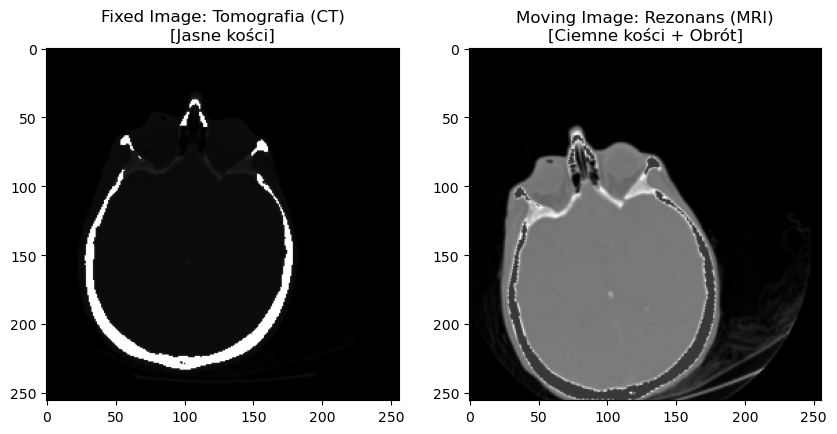

In [38]:
# 1. Przygotowanie danych
base_brain = data.brain()[5, :, :].astype(np.float32)
base_brain = (base_brain - base_brain.min()) / (base_brain.max() - base_brain.min())

# CT (Jasne kości)
ct_np = base_brain.copy()
bone_mask = ct_np > 0.45
ct_np[bone_mask] = 1.0
ct_np[~bone_mask] *= 0.3

# MRI (Ciemne kości)
mri_np = base_brain.copy()
mri_np[bone_mask] = 0.05
mri_np = np.power(mri_np, 0.7)

fixed_ct = sitk.GetImageFromArray(ct_np)
fixed_ct.SetSpacing((1.0, 1.0))
fixed_ct.SetOrigin((0.0, 0.0))

moving_mri_orig = sitk.GetImageFromArray(mri_np)
moving_mri_orig.SetSpacing((1.0, 1.0))
moving_mri_orig.SetOrigin((0.0, 0.0))

# 2. Celowe przesunięcie (Zwróć uwagę na SetCenter!)
transform_true = sitk.Euler2DTransform()
# Ustawiamy środek obrotu w ścisłym centrum głowy!
center_pt = fixed_ct.TransformContinuousIndexToPhysicalPoint(np.array(fixed_ct.GetSize()) / 2.0)
transform_true.SetCenter(center_pt)
transform_true.SetTranslation((12.0, -15.0))
transform_true.SetAngle(np.radians(15))

moving_mri = sitk.Resample(moving_mri_orig, fixed_ct, transform_true, sitk.sitkLinear, 0.0, moving_mri_orig.GetPixelID())

# Wizualizacja
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(sitk.GetArrayFromImage(fixed_ct), cmap='gray')
ax[0].set_title('Fixed Image: Tomografia (CT)\n[Jasne kości]')
ax[1].imshow(sitk.GetArrayFromImage(moving_mri), cmap='gray')
ax[1].set_title('Moving Image: Rezonans (MRI)\n[Ciemne kości + Obrót]')
plt.show()

### 2. Dlaczego błąd średniokwadratowy (mean squares) tutaj FAŁSZUJE wynik?
Przetestujmy zachowanie metryki `MeanSquares` na obrazach o odwrotnym kontraście kości.

In [41]:
R_ms = sitk.ImageRegistrationMethod()
R_ms.SetMetricAsMeanSquares()
R_ms.SetOptimizerAsRegularStepGradientDescent(learningRate=2.0, minStep=1e-4, numberOfIterations=100)
R_ms.SetInterpolator(sitk.sitkLinear)

init_t = sitk.CenteredTransformInitializer(fixed_ct, moving_mri, sitk.Euler2DTransform(), sitk.CenteredTransformInitializerFilter.MOMENTS)
R_ms.SetInitialTransform(init_t)

transform_ms = R_ms.Execute(fixed_ct, moving_mri)
registered_ms = sitk.Resample(moving_mri, fixed_ct, transform_ms, sitk.sitkLinear, 0.0, moving_mri.GetPixelID())

print("Rejestracja Mean Squares zakończona.")

Rejestracja Mean Squares zakończona.


### 3. Prawidłowa rejestracja: informacja wzajemna (mattes mutual information)
Stosujemy `SetMetricAsMattesMutualInformation`. Metryka ta buduje wspólny histogram 2D jasności obu obrazów i dąży do zminimalizowania jego entropii.

In [63]:
R_mi = sitk.ImageRegistrationMethod()

# Ustawiamy Informację Wzajemną Mattesa (50 koszyków histogramu)
R_mi.SetMetricAsMattesMutualInformation(numberOfHistogramBins=50)
R_mi.SetMetricSamplingStrategy(R_mi.RANDOM)
#R_mi.SetMetricSamplingStrategy(R_mi.REGULAR)
R_mi.SetMetricSamplingPercentage(0.2) # Próbkowanie 20% pikseli przyspiesza obliczenia
#R_mi.SetMetricSamplingPercentage(1.0) # Próbkowanie 100% 

# Automatyczne skalowanie wag kąta względem przesunięcia!
#R_mi.SetOptimizerScalesFromPhysicalShift()


# Krok 1: zmniejsz obraz 4-krotnie, Krok 2: 2-krotnie, Krok 3: pełna rozdzielczość
R_mi.SetShrinkFactorsPerLevel(shrinkFactors = [4, 2, 1])
R_mi.SetSmoothingSigmasPerLevel(smoothingSigmas=[2, 1, 0])
R_mi.SmoothingSigmasAreSpecifiedInPhysicalUnitsOn()


# Optymalizator
R_mi.SetOptimizerAsRegularStepGradientDescent(learningRate=2.0, minStep=1e-4, numberOfIterations=200)
R_mi.SetInterpolator(sitk.sitkLinear)

# Inicjalizacja położenia
init_mi = sitk.CenteredTransformInitializer(fixed_ct, moving_mri, sitk.Euler2DTransform(), sitk.CenteredTransformInitializerFilter.MOMENTS)
R_mi.SetInitialTransform(init_mi)

print("Uruchamiam rejestrację z Informacją Wzajemną (Mutual Information)...")
transform_mi = R_mi.Execute(fixed_ct, moving_mri)
registered_mi = sitk.Resample(moving_mri, fixed_ct, transform_mi, sitk.sitkLinear, 0.0, moving_mri.GetPixelID())

print("Sukces!")
print(f"Znalezione parametry: {transform_mi.GetParameters()}")

Uruchamiam rejestrację z Informacją Wzajemną (Mutual Information)...
Sukces!
Znalezione parametry: (-3.249480014150723, -0.03033975596100655, 0.49213478139156497)


### 4. Wizualizacja wielomodalna (szachownica & kompozycja RGB)

Zwykłe odejmowanie pikseli (`CT - MRI`) nie ma sensu, bo obrazy różnią się jasnością tkanki z natury! 
Stosujemy dwie profesjonalne metody oceny dopasowania wielomodalnego:
1. **Szachownica (`sitk.CheckerBoard`):** Obraz dzielony jest na naprzemienne kwadraty z obu skanów. Jeśli krawędzie kości i tkanki przechodzą płynnie przez granice kwadratów – rejestracja jest idealna.
2. **Kompozycja Kolorowa (RGB):** Tomografia w kanale Czerwonym, Rezonans w kanale Zielonym.

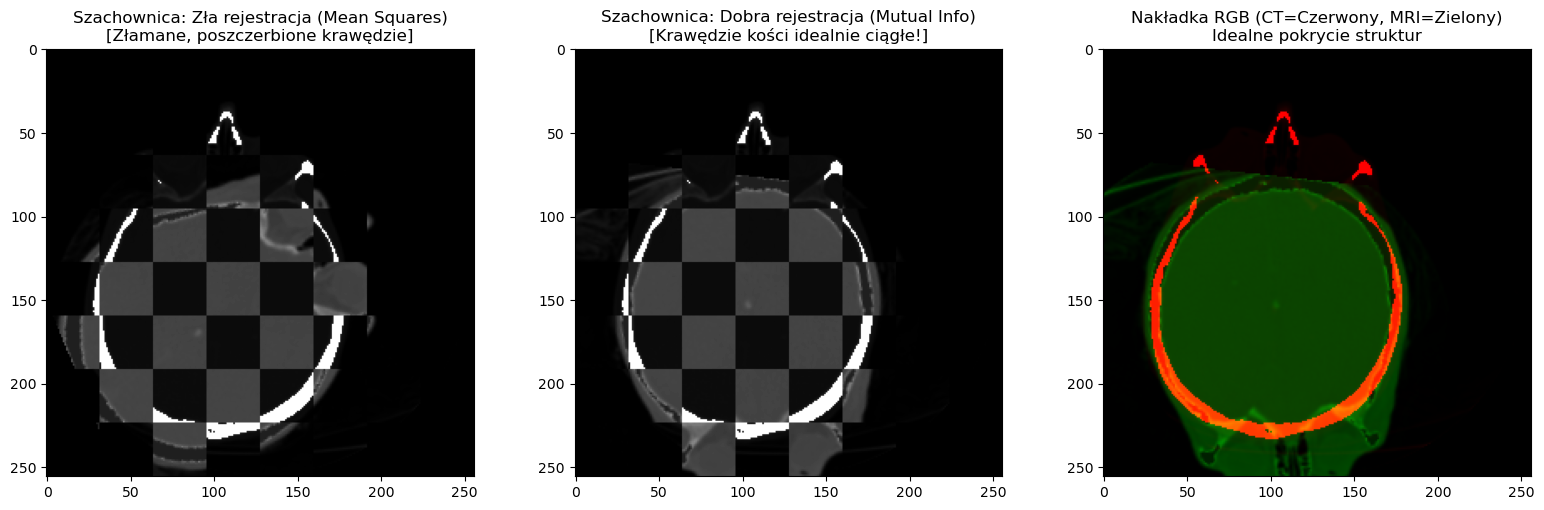

In [66]:
# 1. Generowanie Szachownicy dla rejestracji Mean Squares (złej) oraz Mutual Information (dobrej)
checker_bad = sitk.CheckerBoard(fixed_ct, registered_ms, [8, 8])
checker_good = sitk.CheckerBoard(fixed_ct, registered_mi, [8, 8])

# 2. Kompozycja RGB (CT = Czerwony, MRI = Zielony)
ct_arr = sitk.GetArrayFromImage(fixed_ct)
mri_good_arr = sitk.GetArrayFromImage(registered_mi)

rgb_composite = np.zeros((ct_arr.shape[0], ct_arr.shape[1], 3))
rgb_composite[..., 0] = ct_arr        # Kanał R (CT)
rgb_composite[..., 1] = mri_good_arr # Kanał G (MRI)

# Wyświetlanie wyników
fig, ax = plt.subplots(1, 3, figsize=(16, 5))

ax[0].imshow(sitk.GetArrayFromImage(checker_bad), cmap='gray')
ax[0].set_title('Szachownica: Zła rejestracja (Mean Squares)\n[Złamane, poszczerbione krawędzie]')

ax[1].imshow(sitk.GetArrayFromImage(checker_good), cmap='gray')
ax[1].set_title('Szachownica: Dobra rejestracja (Mutual Info)\n[Krawędzie kości idealnie ciągłe!]')

ax[2].imshow(rgb_composite)
ax[2].set_title('Nakładka RGB (CT=Czerwony, MRI=Zielony)\nIdealne pokrycie struktur')

plt.tight_layout()
plt.show()